### NBA-játékosok statisztikai profiljai (20. feladat)
**Név:** Füzesi Milán  
**Adathalmaz:** [NBA Stats (1947-present)](https://www.kaggle.com/datasets/sumitrodatta/nba-aba-baa-stats)

---

### 1. A probléma felvetése és az adatok előfeldolgozása

A beadandóban az NBA játékosok szezonstatisztikáit vizsgálom. A fő célunk megnézni, hogyan csoportosulnak a játékosok a mutatóik alapján, milyen játékosprofilok (szerepkörök) rajzolódnak ki egy 2D-s térképen, és kik azok a játékosok, akik a játékstílusuk alapján kilógnak a hivatalosan megadott posztjukból (`PG`, `SG`, `SF`, `PF`, `C`).

A fő kérdés mellett **két további saját projektkérdést** is kidolgozok ugyanezen az adathalmazon:
1. **Az NBA játékstílusának változása (Idősoros vizsgálat):** Hogyan alakult át a mezőny dobáskiválasztása (hárompontosok előretörése, tempó) az 1980-as évektől napjainkig, és mikor történt a legélesebb váltás?
2. **Hasonló játékosok keresése (Tartalomalapú ajánlórendszer):** Hogyan tudunk egy adott sztárjátékoshoz (pl. Nikola Jokić, Stephen Curry) Top-5 hasonló játékost ajánlani koszinusz-hasonlóság alapján, miért csalókák a nyers meccsátlagok a skálázott szerepkör-vektorokhoz képest (`Precision@5` kiértékelés), és hogyan találhatók meg az olcsóbb (nem All-Star) pótlások?

#### 1.1. Elemzési döntések és adattisztítás

Mielőtt bármilyen modellt ráfuttatnánk az adatra, tisztázni kell néhány alapvető dolgot az adathalmazzal kapcsolatban:

- **Mi egy sor (elemzési egység)?** Egy sor egy adott játékos egy adott szezonban nyújtott teljesítményét jelenti (*játékos-szezon*).
- **Időszak kiválasztása:** Az adathalmaz 1947-től 2027-ig tartalmaz adatokat. Mivel a kosárlabda stílusa rengeteget változott (régen triplavonal sem volt), a 2027-es szezon pedig még nem ért véget, a profilozáshoz a legutóbbi **5 teljes szezont (2022–2026)** szűrtem le.
- **Csapatváltók (duplikációk) kiszűrése:** Ha valakit szezon közben elcserélnek, az több soron is szerepel ugyanabban az évben (egyszer a régi csapatánál, egyszer az újnál, plusz egy összesített `2TM` / `3TM` soron). Hogy egy játékos egy szezonban csak egyszer számítson, mindenkinél a legtöbb játszott perccel (`mp`) rendelkező összesített sort tartottam meg.
- **Melyik táblát használjuk?** A nyers összpontszámok (`Player Totals`) vagy meccsátlagok (`Player Per Game`) alapján a modell főleg a pályán töltött időt mérné (kezdő sztárok vs. kevés percet kapó cserék). Mivel minket a **játékstílus** érdekel, a **36 percre vetített adatokat (`Per 36 Minutes.csv`)** kötöttem össze a **fejlett mutatókkal (`Advanced.csv`**, pl. *Usage%*, *True Shooting%*, *Assist%*).

> **Megjegyzés a szűréshez:** A 36 percre vetített statisztikáknál csapda a **kis mintás zaj**: ha egy csere egész évben 2 percet játszik és bedob egy kosarat, irreálisan magas (70 feletti) 36 percre vetített pontátlaga lesz. Ezért meghúztam egy határt: **legalább 20 meccs és 500 játszott perc** kell a bekerüléshez. Ezzel viszont **túlélési torzítás (survivorship bias)** lép fel, mert a gyengébb hatékonyságú peremjátékosokat eldobjuk — az eredményeink tehát a tényleges rotációban lévő NBA játékosokra érvényesek.+3

Per 36 tábla mérete: (32697, 32)
Advanced tábla mérete: (33780, 30)

Összes játékos-szezon (2022-2026): 2867
Megtartott (rotációs játékosok):   1851
Kiszűrt (kevés perc / kis minta):  1016


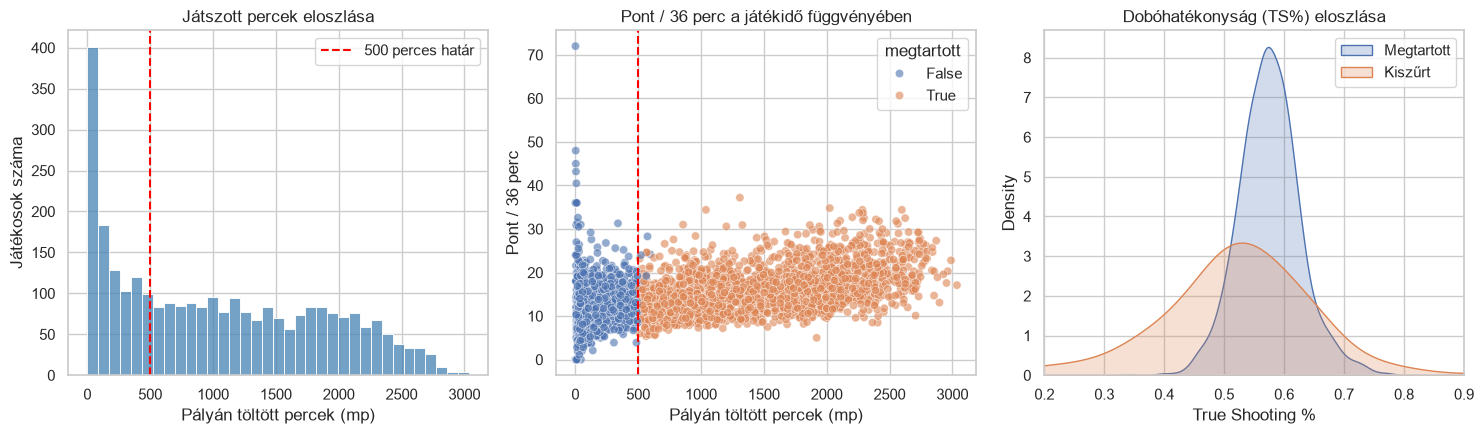


Posztok eloszlása a szűrt adathalmazon:
pos_clean
SG    458
SF    355
PF    351
C     345
PG    342
Name: count, dtype: int64


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

# Adatok betöltése
per_36 = pd.read_csv('data/Per 36 Minutes.csv')
per_game = pd.read_csv('data/Player Per Game.csv')
adv = pd.read_csv('data/Advanced.csv')
all_star = pd.read_csv('data/All-Star Selections.csv')
eos_teams = pd.read_csv('data/End of Season Teams.csv')
awards = pd.read_csv('data/Player Award Shares.csv')

print("Per 36 tábla mérete:", per_36.shape)
print("Advanced tábla mérete:", adv.shape)

# Szűrés a 2022-2026 közötti NBA szezonokra
m_p36 = per_36[(per_36['season'] >= 2022) & (per_36['season'] <= 2026) & (per_36['lg'] == 'NBA')].copy()
m_adv = adv[(adv['season'] >= 2022) & (adv['season'] <= 2026) & (adv['lg'] == 'NBA')].copy()

# Duplikációk (szezon közbeni csapatváltók) kiszűrése: a legtöbb perces (összesített) sort tartjuk meg
dedup_p36 = m_p36.sort_values(['season', 'player_id', 'mp'], ascending=[True, True, False]).drop_duplicates(subset=['season', 'player_id'])
dedup_adv = m_adv.sort_values(['season', 'player_id', 'mp'], ascending=[True, True, False]).drop_duplicates(subset=['season', 'player_id'])

# A két tábla összekötése
adv_cols = ['season', 'player_id', 'per', 'ts_percent', 'x3p_ar', 'f_tr', 
            'orb_percent', 'drb_percent', 'trb_percent', 'ast_percent', 
            'stl_percent', 'blk_percent', 'tov_percent', 'usg_percent', 'bpm', 'vorp']

df_modern = pd.merge(dedup_p36, dedup_adv[adv_cols], on=['season', 'player_id'])

# Ha valakinél két poszt van megadva (pl. PF-C), az elsőt vesszük alapul
df_modern['pos_clean'] = df_modern['pos'].apply(lambda x: str(x).split('-')[0])

# Szűrési feltétel: legalább 20 meccs és 500 perc
df_modern['megtartott'] = (df_modern['g'] >= 20) & (df_modern['mp'] >= 500)

print(f"\nÖsszes játékos-szezon (2022-2026): {len(df_modern)}")
print(f"Megtartott (rotációs játékosok):   {df_modern['megtartott'].sum()}")
print(f"Kiszűrt (kevés perc / kis minta):  {(~df_modern['megtartott']).sum()}")

# Ábra: Miért kellett szűrni, és mit veszítettünk vele?
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Percek eloszlása
sns.histplot(df_modern['mp'], bins=35, ax=axes[0], color='steelblue')
axes[0].axvline(500, color='red', linestyle='--', label='500 perces határ')
axes[0].set_title('Játszott percek eloszlása')
axes[0].set_xlabel('Pályán töltött percek (mp)')
axes[0].set_ylabel('Játékosok száma')
axes[0].legend()

# 2. Kis mintás zaj (Pont / 36 perc vs. játszott percek)
sns.scatterplot(data=df_modern, x='mp', y='pts_per_36_min', hue='megtartott', alpha=0.6, ax=axes[1])
axes[1].axvline(500, color='red', linestyle='--')
axes[1].set_title('Pont / 36 perc a játékidő függvényében')
axes[1].set_xlabel('Pályán töltött percek (mp)')
axes[1].set_ylabel('Pont / 36 perc')

# 3. Túlélési torzítás a dobóhatékonyságban (TS%)
sns.kdeplot(data=df_modern[df_modern['megtartott']], x='ts_percent', fill=True, label='Megtartott', ax=axes[2])
sns.kdeplot(data=df_modern[~df_modern['megtartott']], x='ts_percent', fill=True, label='Kiszűrt', ax=axes[2])
axes[2].set_xlim(0.2, 0.9)
axes[2].set_title('Dobóhatékonyság (TS%) eloszlása')
axes[2].set_xlabel('True Shooting %')
axes[2].legend()

plt.tight_layout()
plt.show()

# Szűrt adathalmaz mentése és a 0 triplát dobó centerek NaN százalékainak kitöltése 0-val
df = df_modern[df_modern['megtartott']].copy().reset_index(drop=True)
df[['x3p_percent', 'x2p_percent', 'ft_percent']] = df[['x3p_percent', 'x2p_percent', 'ft_percent']].fillna(0.0)

print("\nPosztok eloszlása a szűrt adathalmazon:")
print(df['pos_clean'].value_counts())

---

### 2. Magas dimenziós reprezentáció, skálázás és 2D térképek (PCA vs. t-SNE)

A játékosok stílusának leírásához **14 darab, játékidőre normált és fejlett statisztikai mutatót** választottam ki (pontok, támadó/védő lepattanók, gólpasszok, labdaszerzések, blokkok, eladott labdák, 2 és 3 pontos kísérletek, büntetők, valamint *True Shooting%*, *Usage%*, *Assist%* és *3PAr* triplaarány). A névleges posztot (`pos_clean`) a modellek **nem** kapják meg bemenetként, azt csak utólag, ellenőrzésre és színezésre használom.

#### 2.1. Ferde eloszlások és a skálázási döntés (`log1p` + `RobustScaler`)
A távolság-alapú módszerek (PCA, t-SNE, K-Means) érzékenyek az eltérő mértékegységekre és a kiugró értékekre:
- Több mutató erősen jobbra ferde eloszlású (például a `blk_per_36_min` ferdesége 1,93, az `orb_per_36_min` pedig 1,49), mert a mezőny nagy része keveset blokkol vagy szed támadó lepattanót, néhány center viszont kiugróan sokat.
- Az erősen ferde változókon (> 1,0 ferdeség) `log1p` transzformációt alkalmaztam, hogy az arányok számítsanak a nyers különbségek helyett.
- A szokásos `StandardScaler` helyett **`RobustScaler`**-t (medián és IQR alapú skálázást) használtam, így a néhány extrém sztárjátékos nem húzza el a skálát.

#### 2.2. Kétdimenziós térkép: PCA és t-SNE összevetése
A 14 dimenziós teret két különböző megközelítéssel is levetítettem 2D-be:
1. **PCA (Főkomponens-elemzés):** A globális varianciát maximalizálja lineáris kombinációkkal. A főkomponensek súlyaiból (*loadings*) leolvasható a tengelyek szakmai jelentése, és pontosan mérhető a **megőrzött variancia aránya**.
2. **t-SNE:** A lokális szomszédsági viszonyokat próbálja megőrizni (aki közel volt a 14D térben, maradjon közel 2D-ben is). A tengelyeknek itt nincs önálló fizikai jelentése.

A vetítések minőségét a 3. órán tanult **szomszédság-tisztasággal (Neighborhood Purity, $k=15$)** is ellenőriztem, vagyis hogy egy játékos 15 legközelebbi statisztikai szomszédjából hányan játszanak vele azonos hivatalos poszton.

Változók ferdesége (skewness) transzformáció előtt:
blk_per_36_min     1.93
orb_per_36_min     1.49
fta_per_36_min     1.35
ast_percent        1.14
ast_per_36_min     1.09
drb_per_36_min     1.00
stl_per_36_min     0.98
tov_per_36_min     0.78
pts_per_36_min     0.75
usg_percent        0.67
x2pa_per_36_min    0.53
ts_percent         0.20
x3pa_per_36_min   -0.15
x3p_ar            -0.25
dtype: float64

PCA 1. és 2. főkomponens súlyai (Loadings):
                   PC1    PC2
pts_per_36_min   0.372  0.203
orb_per_36_min   0.113 -0.393
drb_per_36_min   0.231 -0.303
ast_per_36_min   0.185  0.266
stl_per_36_min   0.001  0.084
blk_per_36_min   0.120 -0.375
tov_per_36_min   0.360  0.184
x3pa_per_36_min -0.115  0.414
x2pa_per_36_min  0.415 -0.000
fta_per_36_min   0.379  0.019
ts_percent       0.123 -0.232
usg_percent      0.350  0.254
ast_percent      0.207  0.257
x3p_ar          -0.328  0.321

Szomszédság-tisztaság (5 poszt, véletlen szint = 0.20):
 - Eredeti 14D tér: 0.485
 - PCA 2D vetítés: 

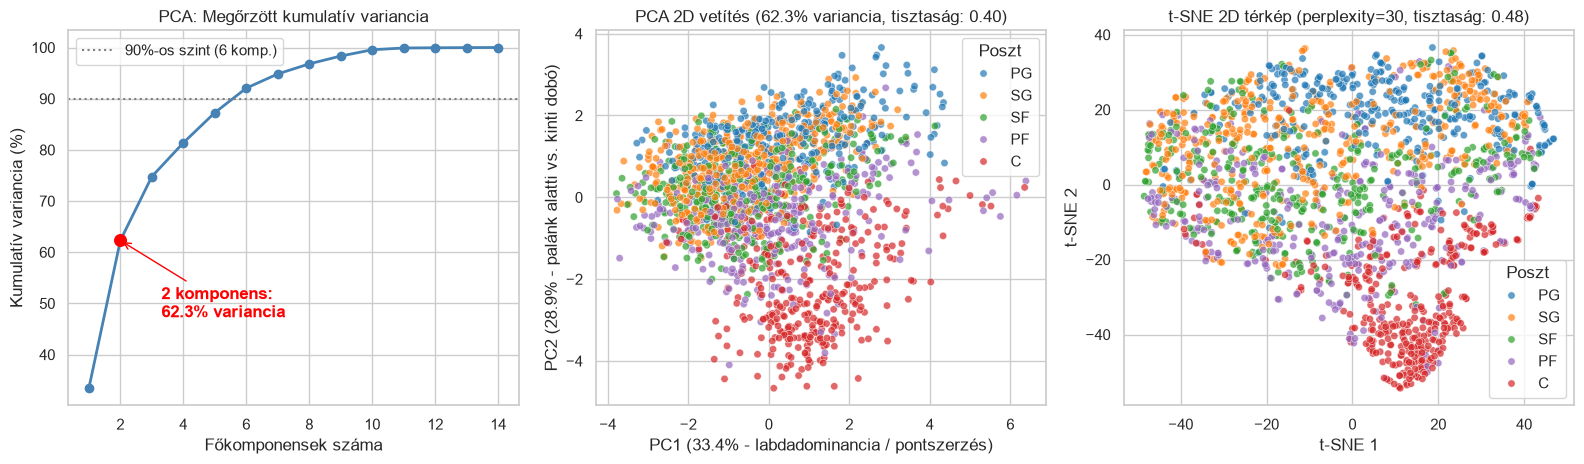

In [6]:
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

# A 14 kiválasztott stílus- és szerepkör-változó
features = [
    'pts_per_36_min', 'orb_per_36_min', 'drb_per_36_min',
    'ast_per_36_min', 'stl_per_36_min', 'blk_per_36_min', 'tov_per_36_min',
    'x3pa_per_36_min', 'x2pa_per_36_min', 'fta_per_36_min',
    'ts_percent', 'usg_percent', 'ast_percent', 'x3p_ar'
]

X_raw = df[features].copy()
print("Változók ferdesége (skewness) transzformáció előtt:")
print(X_raw.skew().sort_values(ascending=False).round(2))

# Erősen jobbra ferde változók (ferdeség > 1.0) log1p transzformációja
skewed_cols = ['blk_per_36_min', 'orb_per_36_min', 'fta_per_36_min', 'ast_percent', 'ast_per_36_min']
X_trans = X_raw.copy()
for col in skewed_cols:
    X_trans[col] = np.log1p(X_trans[col])

# Robusztus skálázás (medián és IQR alapján)
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_trans)

# 1. PCA futtatása a teljes térre és 2D-re
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_) * 100

pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)
df['PC1'], df['PC2'] = X_pca[:, 0], X_pca[:, 1]

# Főkomponensek súlyai (mit jelentenek az új tengelyek?)
loadings = pd.DataFrame(pca_2d.components_.T, index=features, columns=['PC1', 'PC2'])
print("\nPCA 1. és 2. főkomponens súlyai (Loadings):")
print(loadings.round(3))

# 2. t-SNE 2D vetítés
tsne = TSNE(n_components=2, perplexity=30, random_state=0, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_scaled)
df['tSNE1'], df['tSNE2'] = X_tsne[:, 0], X_tsne[:, 1]

# 3. Szomszédság-tisztaság (Purity) számítása (k=15 legközelebbi szomszédra)
def neighborhood_purity(X_space, labels, k=15):
    y = labels.to_numpy(dtype=object)
    nn = NearestNeighbors(n_neighbors=k+1).fit(X_space)
    idx = nn.kneighbors(X_space, return_distance=False)[:, 1:]
    same_pos = (y[idx] == y[:, None]).mean(axis=1)
    return same_pos.mean()

p_14d = neighborhood_purity(X_scaled, df['pos_clean'], k=15)
p_pca = neighborhood_purity(X_pca, df['pos_clean'], k=15)
p_tsne = neighborhood_purity(X_tsne, df['pos_clean'], k=15)

print(f"\nSzomszédság-tisztaság (5 poszt, véletlen szint = 0.20):")
print(f" - Eredeti 14D tér: {p_14d:.3f}")
print(f" - PCA 2D vetítés:  {p_pca:.3f} (megőrzött variancia: {cum_var[1]:.1f}%)")
print(f" - t-SNE 2D térkép: {p_tsne:.3f}")

# Ábrázolás
pos_order = ['PG', 'SG', 'SF', 'PF', 'C']
pos_palette = {'PG': '#1f77b4', 'SG': '#ff7f0e', 'SF': '#2ca02c', 'PF': '#9467bd', 'C': '#d62728'}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# (a) Kumulatív variancia
axes[0].plot(range(1, len(features) + 1), cum_var, marker='o', color='steelblue', linewidth=2)
axes[0].axhline(90, color='gray', linestyle=':', label='90%-os szint (6 komp.)')
axes[0].scatter([2], [cum_var[1]], color='red', s=70, zorder=5)
axes[0].annotate(f'2 komponens:\n{cum_var[1]:.1f}% variancia', xy=(2, cum_var[1]), xytext=(3.3, cum_var[1]-15),
                 arrowprops=dict(arrowstyle='->', color='red'), fontweight='bold', color='red')
axes[0].set_title('PCA: Megőrzött kumulatív variancia')
axes[0].set_xlabel('Főkomponensek száma')
axes[0].set_ylabel('Kumulatív variancia (%)')
axes[0].legend()

# (b) PCA 2D térkép (utólagos poszt-színezéssel)
sns.scatterplot(data=df, x='PC1', y='PC2', hue='pos_clean', hue_order=pos_order, palette=pos_palette, alpha=0.7, s=28, ax=axes[1])
axes[1].set_title(f'PCA 2D vetítés ({cum_var[1]:.1f}% variancia, tisztaság: {p_pca:.2f})')
axes[1].set_xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}% - labdadominancia / pontszerzés)')
axes[1].set_ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}% - palánk alatti vs. kinti dobó)')
axes[1].legend(title='Poszt')

# (c) t-SNE 2D térkép
sns.scatterplot(data=df, x='tSNE1', y='tSNE2', hue='pos_clean', hue_order=pos_order, palette=pos_palette, alpha=0.7, s=28, ax=axes[2])
axes[2].set_title(f't-SNE 2D térkép (perplexity=30, tisztaság: {p_tsne:.2f})')
axes[2].set_xlabel('t-SNE 1')
axes[2].set_ylabel('t-SNE 2')
axes[2].legend(title='Poszt')

plt.tight_layout()
plt.show()

**Mit látunk a 2D térképeken?**
- Az első két főkomponens (`PC1` és `PC2`) a 14 változó teljes varianciájának **62,3%-át** őrzi meg (a 90%-os szinthez 6 főkomponensre van szükség).
- A `PC1` tengely súlyaiból látszik, hogy pozitív irányban a magas *Usage%*, sok kétpontos és büntető kísérlet, valamint sok pont és gólpassz húzza el a pontokat — ez tehát a **labdadomináns támadó szerepkör** tengelye.
- A `PC2` tengely súlyaiból (loadings) látszik, hogy **negatív** irányban a támadó/védő lepattanókat és blokkokat (`orb`, `blk`, `drb` — ezért vannak a piros centerek az ábra alján), **pozitív** irányban pedig a triplakísérleteket és triplaarányt (`x3pa`, `x3p_ar` — hátvédek felül) súlyozza — vagyis a **palánk alatti magasembereket választja szét a kinti dobóktól**.
- A **t-SNE** lokális szomszédság-tisztasága magasabb (**0,482** vs. PCA **0,404**), szinte teljesen visszaadja a 14D tér eredeti szomszédsági tisztaságát (**0,485**). Jól látszik, hogy a centerek (`C`) és az irányítók (`PG`) markánsan elkülönülnek, viszont a mezőnyjátékosok (`SG`, `SF`, `PF`) erősen átfednek egymással, ami előrevetíti, hogy a hagyományos 5 poszt helyett funkcionális klasztereket érdemes keresnünk.

---

### 3. Játékosprofilok feltárása (Klaszterezés) és Poszt-anomáliák

A 2D vetítések (PCA, t-SNE) vizuális áttekintést adtak, de a konkrét csoportok kijelöléséhez a **14 dimenziós skálázott térben** futtattam klaszterezést. A 4. órán tanult módszertan alapján a **K-Means** algoritmust alkalmaztam, kitekintésként pedig összevetettem a sűrűségalapú **DBSCAN** eredménnyel is.

#### 3.1. A klaszterszám ($k$) megválasztása
A $k$ kiválasztásához három szempontot vizsgáltam $k=2 \dots 8$ tartományban:
1. **Inertia (Könyökmódszer):** Klaszteren belüli négyzetes távolságok összege.
2. **Átlagos Silhouette-érték:** A csoportok kompaktságát és elkülönülését méri.
3. **A legkisebb klaszter mérete:** Kezelhetőségi szempontból elvárás, hogy ne keletkezzenek túl apró töredékcsoportok (alsó határnak ~150 játékos-szezont tekintve).

Bár a Silhouette-érték $k=3$-nál tetőzik (ami a *Hátvéd – Mezőnyjátékos – Magasember* hármas felbontásnak felel meg), szakmai szempontból a **$k=5$ klaszterszámot** választottam. Így közvetlenül összevethető a statisztikai felosztás a kosárlabda hagyományos 5 posztjával (`PG, SG, SF, PF, C`), miközben a legkisebb csoport mérete is 277 fő marad.

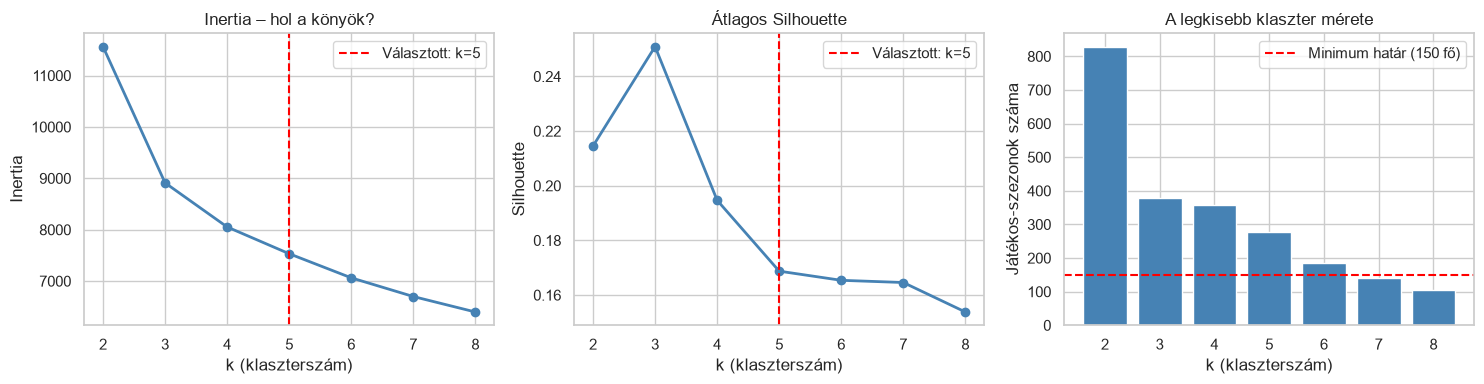

Klaszterek medián értékei eredeti mértékegységben:


,pts_per_36_min,trb_per_36_min,orb_per_36_min,ast_per_36_min,blk_per_36_min,x3pa_per_36_min,usg_percent,ts_percent,x3p_ar
profil_nev,,,,,,,,,
0: Palánk alatti magasember (Big),15.2,10.8,3.6,2.2,1.4,0.9,16.8,0.62,0.08
1: All-round / Játékszervező mindenes,12.5,5.4,1.3,4.3,0.6,4.1,16.1,0.54,0.39
2: Labdadomináns sztár (High-Usage),24.4,6.1,1.0,5.7,0.5,6.0,28.0,0.58,0.33
3: Dinamikus kinti pontszerző,18.1,4.8,0.9,3.9,0.4,6.6,21.6,0.56,0.46
4: 3&D / Kinti dobó specialista,13.3,5.1,1.1,2.2,0.5,6.2,15.3,0.57,0.59


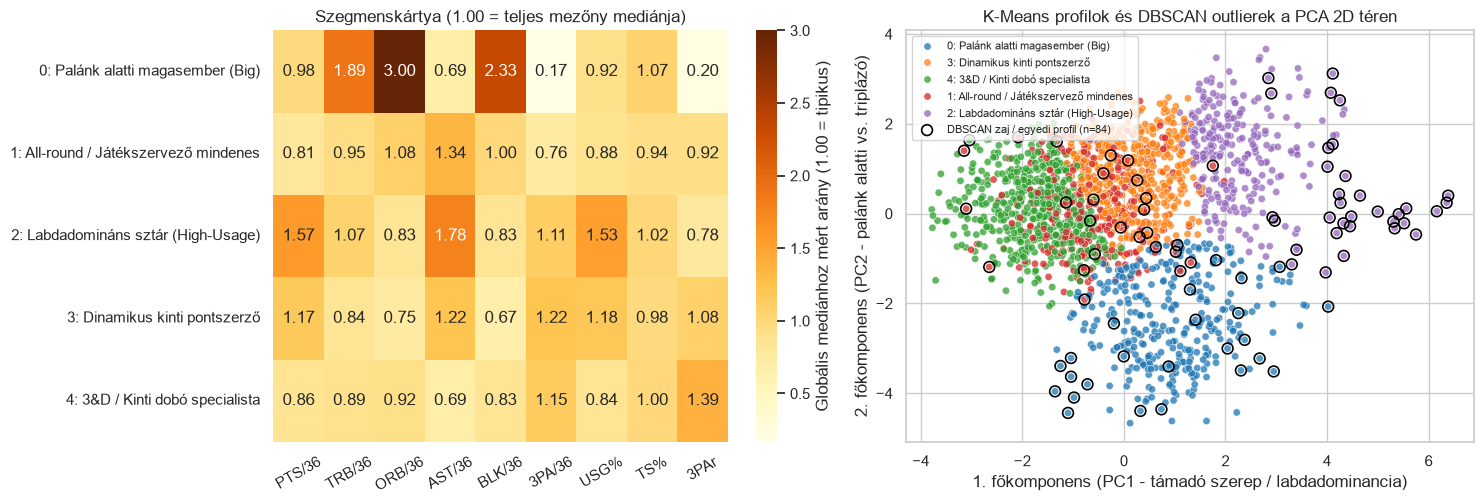


Kereszttábla: Statisztikai profilok vs. Hivatalos posztok (pos_clean):


pos_clean,C,PF,PG,SF,SG
profil_nev,,,,,
0: Palánk alatti magasember (Big),262,66,1,16,0
1: All-round / Játékszervező mindenes,4,47,104,57,85
2: Labdadomináns sztár (High-Usage),33,52,94,44,54
3: Dinamikus kinti pontszerző,20,60,105,82,150
4: 3&D / Kinti dobó specialista,26,126,38,156,169



--- PÉLDÁK POSZT-ANOMÁLIÁKRA (Nem illenek a megadott posztjukhoz) ---

1) Centerek (C), akik a 'Labdadomináns sztár / irányító' (2-es) profilba esnek (Point Centerek):


,season,player,team,pos_clean,pts_per_36_min,trb_per_36_min,ast_per_36_min,usg_percent
1650,2026,Nikola Jokić,DEN,C,28.6,13.3,11.1,30.4
1020,2024,Domantas Sabonis,SAC,C,19.6,13.8,8.3,22.2
1774,2026,Alperen Şengün,HOU,C,22.0,9.6,6.7,26.6
832,2024,Joel Embiid,PHI,C,37.2,11.8,6.0,39.6
175,2022,LeBron James,LAL,C,29.3,7.9,6.0,32.3



2) Centerek (C), akik a '3&D / Kinti dobó specialista' (4-es) profilba esnek (Stretch 5):


,season,player,team,pos_clean,pts_per_36_min,trb_per_36_min,x3pa_per_36_min,x3p_ar,blk_per_36_min
250,2022,Mike Muscala,OKC,C,20.9,7.8,9.9,0.657,1.6
1252,2025,Jay Huff,MEM,C,21.1,6.2,9.6,0.656,2.7
1626,2026,Al Horford,GSW,C,13.8,8.1,7.6,0.633,1.9
1807,2026,Myles Turner,MIL,C,15.9,7.1,7.2,0.594,2.2
1849,2026,Guerschon Yabusele,2TM,C,13.3,8.4,7.0,0.628,0.6



3) Hátvédek és kiscsatárok (PG/SF), akik a 'Palánk alatti magasember' (0-s) profilba esnek:


,season,player,team,pos_clean,pts_per_36_min,trb_per_36_min,orb_per_36_min,blk_per_36_min,x3p_ar
1072,2024,Jabari Walker,POR,SF,13.5,10.8,3.2,0.5,0.273
1052,2024,Amen Thompson,HOU,SF,15.4,10.6,3.8,1.0,0.130
45,2022,Chris Boucher,TOR,SF,16.1,10.5,3.8,1.6,0.397
1529,2026,Justin Champagnie,WAS,SF,15.6,10.0,3.8,1.1,0.359
540,2023,Jalen Johnson,ATL,SF,13.6,9.7,1.8,1.2,0.323


In [3]:
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# 1. k-diagnosztika (k = 2..8) a 14D skálázott téren
k_range = range(2, 9)
inertias, silhouettes, min_sizes = [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels_k))
    min_sizes.append(pd.Series(labels_k).value_counts().min())

# k-diagnosztikai ábra
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
axes[0].plot(list(k_range), inertias, marker='o', color='steelblue', linewidth=2)
axes[0].axvline(5, color='red', linestyle='--', label='Választott: k=5')
axes[0].set_title('Inertia – hol a könyök?')
axes[0].set_xlabel('k (klaszterszám)')
axes[0].set_ylabel('Inertia')
axes[0].legend()

axes[1].plot(list(k_range), silhouettes, marker='o', color='steelblue', linewidth=2)
axes[1].axvline(5, color='red', linestyle='--', label='Választott: k=5')
axes[1].set_title('Átlagos Silhouette')
axes[1].set_xlabel('k (klaszterszám)')
axes[1].set_ylabel('Silhouette')
axes[1].legend()

axes[2].bar(list(k_range), min_sizes, color='steelblue')
axes[2].axhline(150, color='red', linestyle='--', label='Minimum határ (150 fő)')
axes[2].set_title('A legkisebb klaszter mérete')
axes[2].set_xlabel('k (klaszterszám)')
axes[2].set_ylabel('Játékos-szezonok száma')
axes[2].legend()

plt.tight_layout()
plt.show()

# 2. Választott K-Means (k=5) és DBSCAN futtatása
km5 = KMeans(n_clusters=5, random_state=42, n_init=20)
df['cluster'] = km5.fit_predict(X_scaled)

# DBSCAN: sűrű környezeteket keres, a ritka szupersztárokat/specialistákat zajként (-1) jelöli
db = DBSCAN(eps=1.8, min_samples=15).fit(X_scaled)
df['dbscan_zaj'] = (db.labels_ == -1)

# Klaszterek elnevezése a centroidok/mediánok szakmai profilja alapján
cluster_names = {
    0: '0: Palánk alatti magasember (Big)',
    1: '1: All-round / Játékszervező mindenes',
    2: '2: Labdadomináns sztár (High-Usage)',
    3: '3: Dinamikus kinti pontszerző',
    4: '4: 3&D / Kinti dobó specialista'
}
df['profil_nev'] = df['cluster'].map(cluster_names)

# 3. Szegmenskártya (globális mediánhoz viszonyított arányok) és PCA kommunikációs nézet
card_cols = ['pts_per_36_min', 'trb_per_36_min', 'orb_per_36_min', 'ast_per_36_min', 
             'blk_per_36_min', 'x3pa_per_36_min', 'usg_percent', 'ts_percent', 'x3p_ar']
card_labels = ['PTS/36', 'TRB/36', 'ORB/36', 'AST/36', 'BLK/36', '3PA/36', 'USG%', 'TS%', '3PAr']

global_med = df[card_cols].median()
cluster_med = df.groupby('profil_nev')[card_cols].median()
ratio_card = cluster_med.divide(global_med, axis=1)

print("Klaszterek medián értékei eredeti mértékegységben:")
display(cluster_med.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Szegmenskártya hőtérkép
sns.heatmap(ratio_card, annot=True, fmt='.2f', cmap='YlOrBr', 
            cbar_kws={'label': 'Globális mediánhoz mért arány (1.00 = tipikus)'}, ax=axes[0])
axes[0].set_xticklabels(card_labels, rotation=30)
axes[0].set_title('Szegmenskártya (1.00 = teljes mezőny mediánja)')
axes[0].set_ylabel('')

# PCA 2D kommunikációs nézet a K-Means csoportokkal és DBSCAN outlierekkel
sns.scatterplot(data=df, x='PC1', y='PC2', hue='profil_nev', palette='tab10', alpha=0.75, s=28, ax=axes[1])
noise_pts = df[df['dbscan_zaj']]
axes[1].scatter(noise_pts['PC1'], noise_pts['PC2'], facecolors='none', edgecolors='black', 
                s=60, linewidth=1.2, label=f'DBSCAN zaj / egyedi profil (n={len(noise_pts)})')
axes[1].set_title('K-Means profilok és DBSCAN outlierek a PCA 2D téren')
axes[1].set_xlabel('1. főkomponens (PC1 - támadó szerep / labdadominancia)')
axes[1].set_ylabel('2. főkomponens (PC2 - palánk alatti vs. triplázó)')
axes[1].legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.show()

# 4. Kereszttábla: Hivatalos posztok vs. K-Means statisztikai profilok
print("\nKereszttábla: Statisztikai profilok vs. Hivatalos posztok (pos_clean):")
display(pd.crosstab(df['profil_nev'], df['pos_clean'][['C', 'PF', 'SF', 'SG', 'PG']] if False else df['pos_clean']))

# 5. Konkrét poszt-anomáliák (Positionless Basketball példák) kigyűjtése
print("\n--- PÉLDÁK POSZT-ANOMÁLIÁKRA (Nem illenek a megadott posztjukhoz) ---")

print("\n1) Centerek (C), akik a 'Labdadomináns sztár / irányító' (2-es) profilba esnek (Point Centerek):")
anom_c_star = df[(df['cluster'] == 2) & (df['pos_clean'] == 'C')].sort_values('ast_per_36_min', ascending=False)
display(anom_c_star[['season', 'player', 'team', 'pos_clean', 'pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'usg_percent']].drop_duplicates('player').head(5))

print("\n2) Centerek (C), akik a '3&D / Kinti dobó specialista' (4-es) profilba esnek (Stretch 5):")
anom_c_3d = df[(df['cluster'] == 4) & (df['pos_clean'] == 'C')].sort_values('x3pa_per_36_min', ascending=False)
display(anom_c_3d[['season', 'player', 'team', 'pos_clean', 'pts_per_36_min', 'trb_per_36_min', 'x3pa_per_36_min', 'x3p_ar', 'blk_per_36_min']].drop_duplicates('player').head(5))

print("\n3) Hátvédek és kiscsatárok (PG/SF), akik a 'Palánk alatti magasember' (0-s) profilba esnek:")
anom_g_big = df[(df['cluster'] == 0) & (df['pos_clean'].isin(['PG', 'SF']))].sort_values('trb_per_36_min', ascending=False)
display(anom_g_big[['season', 'player', 'team', 'pos_clean', 'pts_per_36_min', 'trb_per_36_min', 'orb_per_36_min', 'blk_per_36_min', 'x3p_ar']].drop_duplicates('player').head(5))

#### 3.2. A kapott játékosprofilok és a poszt-anomáliák értelmezése

A szegmenskártya és a kereszttábla alapján 5 jól elkülönülő funkcionális szerepkör rajzolódik ki:

1. **0: Palánk alatti magasember (Big / Rim Protector – 345 eset):** A gyűrű közelében dolgozó centerek (`C`: 262) és erőcsatárok (`PF`: 66). A támadó lepattanózásuk a ligamedián **3,0-szorosa** (`3,6 ORB/36`), a blokkolásuk **2,33-szorosa** (`1,4 BLK/36`), triplát viszont szinte egyáltalán nem vállalnak (`3PAr`: 0,08).
2. **1: All-round / Játékszervező mindenes (Connector – 297 eset):** Alacsonyabb ponttermésű (`12,5 PTS/36`), de sokoldalú csapatjátékosok, akik átlag felett passzolnak (**1,34x** `AST/36`) és kiveszik a részüket a lepattanózásból is.
3. **2: Labdadomináns sztár (High-Usage Creator – 277 eset):** A csapatok első számú támadó opciói (`24,4 PTS/36` – **1,57x**, `28,0% Usage` – **1,53x**, `5,7 AST/36` – **1,78x**). A DBSCAN eredménye is megerősíti, hogy ennek a csoportnak a szélén helyezkednek el a statisztikailag egyedi szupersztárok (fekete körrel jelölt *zaj* pontok).
4. **3: Dinamikus kinti pontszerző (Scoring Guard/Wing – 417 eset):** Másodlagos labdakezelők és dobóhátvédek, akik átlag feletti pontot (`18,1 PTS/36`) és triplakísérletet (`6,6 3PA/36`) hoznak közepes labdabirtoklás mellett.
5. **4: 3&D / Kinti dobó specialista (Floor Spacer – 515 eset):** A legnépesebb csoport. Labda nélkül dolgozó kiegészítő játékosok, akiknél alacsony a *Usage%* (`15,3%`) és a gólpassz (`2,2 AST/36`), viszont a mezőnykísérleteik **59%-a hárompontos** (**1,39x** a ligamediánhoz képest).

**Kik nem illenek a hivatalos posztjukhoz? (Poszt-anomáliák):**
- **„Point Centerek” (Center poszt, mégis 2-es Labdadomináns sztár / irányító profil):** *Nikola Jokić* (`8,5 AST/36`, `29,1 PTS/36`), *Domantas Sabonis* (`8,3 AST/36`) és *Alperen Şengün* (`5,5 AST/36`). Bár hivatalosan `C` poszton szerepelnek, irányítókat megszégyenítő gólpassz- és labdabirtoklási mutatóik miatt a modell a labdadomináns kreátorok közé sorolja őket.
- **„Stretch 5” centerek (Center poszt, mégis 4-es 3&D kinti dobó profil):** *Brook Lopez* (`6,0 3PA/36`, a dobásainak 53,5%-a tripla, miközben `2,8 BLK/36`-ot átlagol), *Al Horford* vagy *Mike Muscala*. Támadásban nem a palánk alatt, hanem a triplavonalon túl helyezkednek el.
- **Palánk alatt domináló hátvédek/bedobók (PG/SF poszt, mégis 0-s Magasember profil):** *Amen Thompson* (Houston, `PG`/`SF` poszt) `10,6` lepattanót (ebből `3,8` támadó lepattanó!) szed 36 percre, és szinte kizárólag a gyűrű közeléből fejez be (`3PAr`: 0,11–0,13). Hasonlóan *Chris Boucher* vagy *Jalen Johnson* (`SF` megjelöléssel) valójában magasember-szerepkört töltenek be.
- **Mindenes erőcsatárok és lepattanózó hátvédek (1-es profil):** *Draymond Green* (`PF` létére `8,0 AST/36`-ot oszt ki irányítóként) és *Josh Hart* (`SG`/`SF` létére `9,0 TRB/36`-ot szed magasemberként) szintén feloldják a hagyományos poszthatárokat.

---

### 4. Első szabadon választott szempont: Az NBA játékstílusának változása (1980–2026)

Az első saját projektkérdésemben azt vizsgálom, **hogyan alakult át a liga játékstílusa és a posztok szerepköre az időben**, különös tekintettel a hárompontos dobások előretörésére (*Pace-and-Space* korszakváltás). 

A 8. órai idősorelemzés tananyagára építve:
- A hárompontos vonal bevezetésétől (**1980-tól 2026-ig**, 47 szezonon át) vizsgálom a rotációs játékosok ($\ge 20$ meccs, $\ge 500$ perc) szezononkénti átlagos mutatóit.
- Elkészítem a dobáskiválasztás idősorát, egy **posztonkénti vizuális idősor-hőtérképet (Heatmap)**, valamint a szezonok közötti **koszinusz-hasonlósági (Cosine Similarity)** mátrixot, amellyel kimutatható, mikor történtek éles korszakváltások az NBA-ben.

Szezononkénti átlagok néhány kiemelt évből (1980–2026):


,x3pa_per_36_min,x2pa_per_36_min,fta_per_36_min,pts_per_36_min,ast_per_36_min,trb_per_36_min,ts_percent,x3p_ar
season,,,,,,,,
1980,0.41,12.72,3.99,15.66,3.78,6.57,0.52,0.03
1990,0.95,11.49,4.03,15.06,3.55,6.37,0.53,0.07
2000,2.04,9.78,3.55,13.92,3.19,6.32,0.52,0.17
2010,2.72,9.07,3.43,14.34,3.02,6.16,0.54,0.23
2015,3.32,8.81,3.23,14.38,3.11,6.47,0.53,0.27
2020,4.97,7.86,3.25,16.08,3.47,6.67,0.56,0.39
2026,5.45,7.53,3.35,16.75,3.86,6.55,0.58,0.42


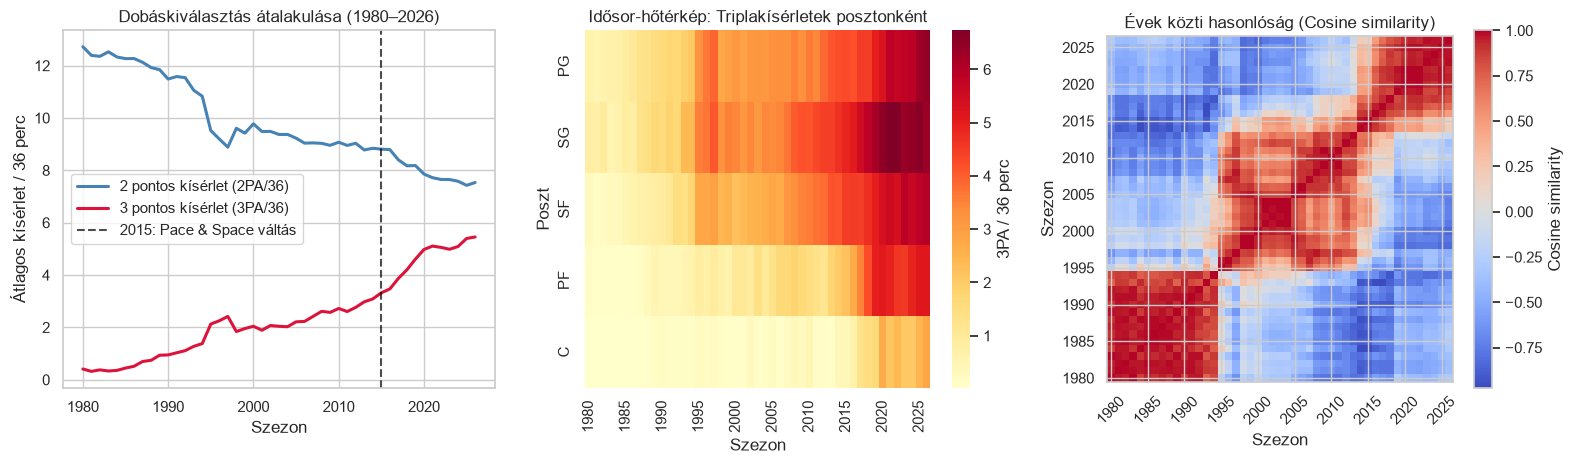

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# 1. Történelmi adatok szűrése 1980 és 2026 között (NBA liga, deduplikálva, >=20 meccs és >=500 perc)
hist_p36 = per_36[(per_36['season'] >= 1980) & (per_36['season'] <= 2026) & (per_36['lg'] == 'NBA')].copy()
hist_adv = adv[(adv['season'] >= 1980) & (adv['season'] <= 2026) & (adv['lg'] == 'NBA')].copy()

dedup_hp36 = hist_p36.sort_values(['season', 'player_id', 'mp'], ascending=[True, True, False]).drop_duplicates(subset=['season', 'player_id'])
dedup_hadv = hist_adv.sort_values(['season', 'player_id', 'mp'], ascending=[True, True, False]).drop_duplicates(subset=['season', 'player_id'])

df_hist = pd.merge(dedup_hp36, dedup_hadv[['season', 'player_id', 'ts_percent', 'x3p_ar', 'usg_percent', 'ast_percent']], on=['season', 'player_id'])
df_hist = df_hist[(df_hist['g'] >= 20) & (df_hist['mp'] >= 500)].copy()
df_hist['pos_clean'] = df_hist['pos'].apply(lambda x: str(x).split('-')[0])

# Szezononkénti átlagok kiszámítása
ts_cols = ['x3pa_per_36_min', 'x2pa_per_36_min', 'fta_per_36_min', 'pts_per_36_min', 
           'ast_per_36_min', 'trb_per_36_min', 'ts_percent', 'x3p_ar']
yearly_stats = df_hist.groupby('season')[ts_cols].mean()

print("Szezononkénti átlagok néhány kiemelt évből (1980–2026):")
display(yearly_stats.loc[[1980, 1990, 2000, 2010, 2015, 2020, 2026]].round(2))

# 2. Posztonkénti triplakísérletek (3PA/36) alakulása az évek során (Heatmap mátrix)
pos_3pa = df_hist[df_hist['pos_clean'].isin(['PG', 'SG', 'SF', 'PF', 'C'])].pivot_table(
    index='pos_clean', columns='season', values='x3pa_per_36_min', aggfunc='mean'
).reindex(['PG', 'SG', 'SF', 'PF', 'C'])

# 3. Évek közötti koszinusz-hasonlóság (standardizált szezonprofilok alapján)
yearly_scaled = StandardScaler().fit_transform(yearly_stats)
cos_sim_years = cosine_similarity(yearly_scaled)
years_list = yearly_stats.index.tolist()

# Ábrázolás 3 panelen
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# (a) 2PA vs 3PA idősor
axes[0].plot(yearly_stats.index, yearly_stats['x2pa_per_36_min'], label='2 pontos kísérlet (2PA/36)', color='steelblue', linewidth=2.2)
axes[0].plot(yearly_stats.index, yearly_stats['x3pa_per_36_min'], label='3 pontos kísérlet (3PA/36)', color='crimson', linewidth=2.2)
axes[0].axvline(2015, color='black', linestyle='--', alpha=0.7, label='2015: Pace & Space váltás')
axes[0].set_title('Dobáskiválasztás átalakulása (1980–2026)')
axes[0].set_xlabel('Szezon')
axes[0].set_ylabel('Átlagos kísérlet / 36 perc')
axes[0].legend()

# (b) Idősor-hőtérkép posztonként
sns.heatmap(pos_3pa, cmap='YlOrRd', cbar_kws={'label': '3PA / 36 perc'}, ax=axes[1], xticklabels=5)
axes[1].set_title('Idősor-hőtérkép: Triplakísérletek posztonként')
axes[1].set_xlabel('Szezon')
axes[1].set_ylabel('Poszt')

# (c) Koszinusz-hasonlóság az évek között
im = axes[2].imshow(cos_sim_years, cmap='coolwarm', interpolation='nearest', origin='lower')
plt.colorbar(im, ax=axes[2], label='Cosine similarity')
tick_idx = np.arange(0, len(years_list), 5)
axes[2].set_xticks(tick_idx)
axes[2].set_xticklabels([years_list[i] for i in tick_idx], rotation=45)
axes[2].set_yticks(tick_idx)
axes[2].set_yticklabels([years_list[i] for i in tick_idx])
axes[2].set_title('Évek közti hasonlóság (Cosine similarity)')
axes[2].set_xlabel('Szezon')
axes[2].set_ylabel('Szezon')

plt.tight_layout()
plt.show()

**Az idősoros vizsgálat eredményei:**
- **Trend és struktúraváltás:** 1980-ban egy átlagos rotációs játékos 36 percre vetítve `12,72` kétpontost és mindössze `0,41` hárompontost dobott rá (`3PAr`: 3%). 2026-ra a kétpontosok száma `7,53`-ra csökkent, a triplakísérleteké pedig `5,45`-re nőtt (a dobások **42%-a** hárompontos), miközben a dobóhatékonyság (`TS%`) 52%-ról **58%-ra** javult. (Az 1995–1997 közötti kisebb kiugrást az okozza, hogy az NBA ebben a három szezonban ideiglenesen közelebb hozta a triplavonalat).
- **Posztok átalakulása a hőtérképen:** A középső hőtérképen látszik, hogy 2015 után nemcsak a hátvédek (`PG`, `SG`), hanem az erőcsatárok (`PF`) és a centerek (`C`) is tömegesen kezdtek triplát dobni: a centerek átlaga a 2000-es `0,12` és a 2015-ös `0,44` után 2026-ra **2,85 triplakísérlet/36 percre** ugrott (ez a *Stretch Big* szerepkör megjelenése).
- **Korszakok a Cosine Similarity mátrixon:** A jobb oldali hasonlósági mátrixon három nagy, egymástól élesen elválasztott korszak (piros blokk) rajzolódik ki: az **1980–1994** közötti klasszikus palánk alatti éra, az **1995–2014** közötti középtávoli korszak, valamint a **2015–2026** közötti modern *Pace-and-Space* éra.

---

### 5. Második szabadon választott szempont: Hasonló játékosok keresése (Tartalomalapú ajánlórendszer)

A második saját projektkérdésemben egy gyakorlati csapatvezetői (scouting / GM) problémát vizsgálok a **2. órán ( Koszinusz-hasonlóság, Jelöltlista csapdái, Precision@K)** és az **5. órán (Tartalomalapú ajánlórendszerek)** tanult módszerekkel:
> *Hogyan tudunk egy adott sztárjátékoshoz (pl. Nikola Jokić, Stephen Curry) Top-5 hasonló játékost ajánlani a statisztikai profiljuk alapján, és miért döntő a választott reprezentáció?*

#### 5.1. Két reprezentáció összehasonlítása és a jelöltlista tisztítása
Két különböző vektorreprezentációt hasonlítok össze koszinusz-hasonlósággal ($\cos \theta$):
1. **Naiv reprezentáció (Nyers meccsátlagok – 5D):** A hagyományos meccsenkénti box-score mutatók (`PTS`, `TRB`, `AST`, `STL`, `BLK`) nyers vektorai.
2. **Szerepkör-alapú reprezentáció (Skálázott stílusvektor – 14D):** A 2. fejezetben előállított `log1p` + `RobustScaler` transzformált 14 dimenziós tér, ahol a 0 érték a liga mediánját jelenti, így a vektorok iránya azt mutatja, **milyen jellemzőkben tér el a játékos a tipikus NBA szinttől**.

**A jelöltlista szűrése (2. óra tanulságai alapján):**
- **Önmagára találás és több-szezonos duplikátumok kizárása:** Mivel egy játékosnak több szezonja is szerepel a táblában (2022–2026), szűrés nélkül egy játékos legjobb találatai saját korábbi/későbbi szezonjai lennének. Ezért a lekérdezett játékos összes szezonját kizárom a jelöltek közül, és minden jelöltből csak a legmagasabb hasonlóságú szezont tartom meg.
- Mellékelem az `All-Star Selections.csv` alapján, hogy az ajánlott játékos volt-e All-Star az adott évben — így külön azonosíthatók a „kis költségvetésű” (nem All-Star, de azonos stílusú) pótlások.

=== LEKÉRDEZÉS: Nikola Jokić (2024, Poszt: C, Profil: 2: Labdadomináns sztár (High-Usage)) ===

A) Top-5 ajánlás SKÁLÁZOTT 14D STÍLUSVEKTOR alapján (Valódi szerepkör-társak):


,season,player,team,pos_clean,cos_style,pts_per_36_min,trb_per_36_min,ast_per_36_min,usg_percent,all_star
751,2024,Giannis Antetokounmpo,MIL,PF,0.960,31.2,11.8,6.7,33.0,True
1024,2024,Alperen Şengün,HOU,C,0.932,23.4,10.4,5.5,27.0,False
832,2024,Joel Embiid,PHI,C,0.921,37.2,11.8,6.0,39.6,True
1647,2026,Jalen Johnson,ATL,SF,0.921,23.0,10.5,8.0,27.0,True
312,2022,Pascal Siakam,TOR,PF,0.901,21.7,8.1,5.0,25.8,False



B) Top-5 ajánlás NYERS MECCSÁTLAGOK alapján (Arány-csapda alacsony volumenű játékosokkal):


,season,player,team,pos_clean,cos_raw,pts_per_36_min,trb_per_36_min,ast_per_36_min,usg_percent,all_star
1418,2025,Max Strus,CLE,SF,1.000,13.3,6.1,4.5,14.7,False
1647,2026,Jalen Johnson,ATL,SF,1.000,23.0,10.5,8.0,27.0,True
481,2023,Josh Giddey,OKC,PF,1.000,19.2,9.1,7.1,24.6,False
1774,2026,Alperen Şengün,HOU,C,0.999,22.0,9.6,6.7,26.6,True
396,2023,Scottie Barnes,TOR,SF,0.999,15.8,6.9,5.0,20.3,False



=== LEKÉRDEZÉS: Stephen Curry (2026, Poszt: PG) - Skálázott 14D Top-5 ajánlás ===


,season,player,team,pos_clean,cos_style,pts_per_36_min,trb_per_36_min,ast_per_36_min,usg_percent,all_star
1197,2025,Anthony Edwards,MIN,SG,0.959,27.3,5.6,4.5,31.4,True
567,2023,Damian Lillard,POR,PG,0.954,31.9,4.7,7.3,33.8,True
1363,2025,Jordan Poole,WAS,SG,0.952,25.0,3.7,5.5,29.0,False
1479,2026,Nickeil Alexander-Walker,ATL,SG,0.941,22.5,3.7,4.0,23.9,False
1336,2025,Trey Murphy III,NOP,SF,0.938,21.8,5.2,3.7,23.7,False



Globális értékelés (n = 1851 lekérdezés átlaga):
 - Skálázott 14D stílusvektor -> Szerepkör Precision@5: 79.1%, Poszt Precision@5: 44.6%
 - Nyers 5D meccsátlagok      -> Szerepkör Precision@5: 47.4%, Poszt Precision@5: 46.0%


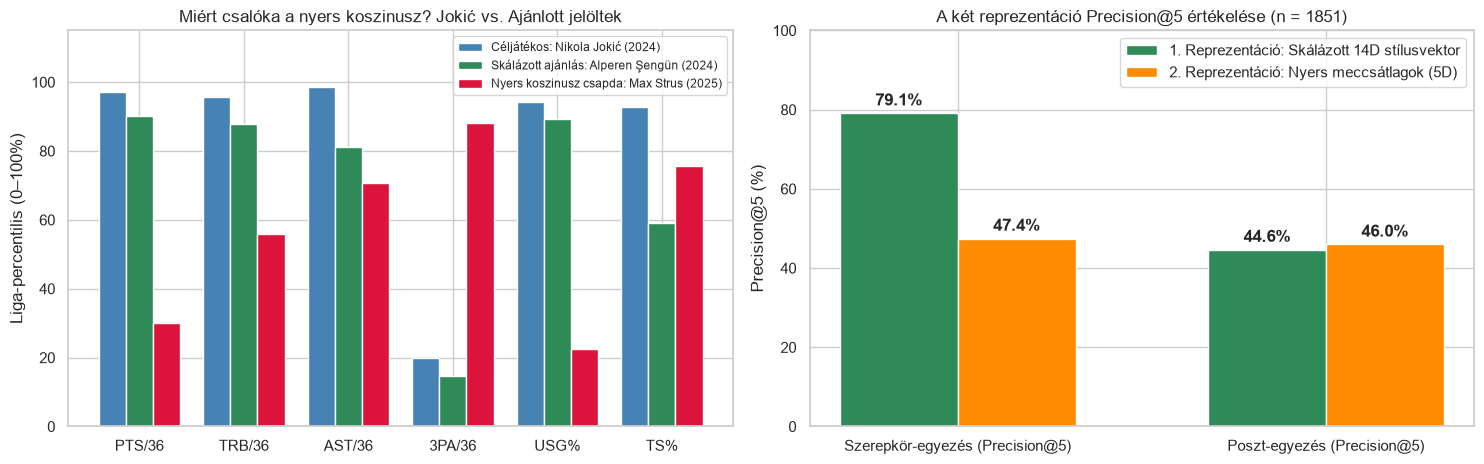

In [5]:
# 1. Meccsenkénti nyers átlagok (Per Game) és All-Star címkék hozzákötése a szűrt df táblához
dedup_pg = (per_game[(per_game['season'] >= 2022) & (per_game['season'] <= 2026) & (per_game['lg'] == 'NBA')]
            .sort_values(['season', 'player_id', 'mp_per_game'], ascending=[True, True, False])
            .drop_duplicates(subset=['season', 'player_id']))

df = pd.merge(df, dedup_pg[['season', 'player_id', 'pts_per_game', 'trb_per_game', 
                            'ast_per_game', 'stl_per_game', 'blk_per_game']], on=['season', 'player_id'])

as_pairs = set(zip(all_star['season'], all_star['player_id']))
df['all_star'] = df.apply(lambda r: (r['season'], r['player_id']) in as_pairs, axis=1)

# 2. Koszinusz-hasonlósági mátrixok kiszámítása a két reprezentációra
# 1. Reprezentáció: 14D RobustScaler stílusvektor
sim_style = cosine_similarity(X_scaled)

# 2. Reprezentáció: 5D nyers meccsátlagok (PTS, TRB, AST, STL, BLK)
raw_pg_cols = ['pts_per_game', 'trb_per_game', 'ast_per_game', 'stl_per_game', 'blk_per_game']
sim_raw = cosine_similarity(df[raw_pg_cols])

# Ajánló függvény (Top-K jelöltlista, önmaga és duplikátumok kiszűrésével)
def get_recommendations(player_name, season=2024, top_k=5):
    idx = df[(df['player'] == player_name) & (df['season'] == season)].index[0]
    
    cols_show = ['season', 'player', 'team', 'pos_clean', 'profil_nev', 
                 'pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'usg_percent', 'all_star']
    res = df[cols_show].copy()
    res['cos_style'] = sim_style[idx]
    res['cos_raw'] = sim_raw[idx]
    
    # Saját maga (összes szezonja) kizárása
    res = res[res['player'] != player_name]
    
    top_style = res.sort_values('cos_style', ascending=False).drop_duplicates('player').head(top_k)
    top_raw = res.sort_values('cos_raw', ascending=False).drop_duplicates('player').head(top_k)
    return df.loc[idx], top_style, top_raw

# Példa 1: Nikola Jokić (2024)
target_jokic, top_s_jokic, top_r_jokic = get_recommendations('Nikola Jokić', season=2024, top_k=5)
print(f"=== LEKÉRDEZÉS: {target_jokic['player']} ({target_jokic['season']}, Poszt: {target_jokic['pos_clean']}, Profil: {target_jokic['profil_nev']}) ===")
print("\nA) Top-5 ajánlás SKÁLÁZOTT 14D STÍLUSVEKTOR alapján (Valódi szerepkör-társak):")
display(top_s_jokic[['season', 'player', 'team', 'pos_clean', 'cos_style', 'pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'usg_percent', 'all_star']].round(3))

print("\nB) Top-5 ajánlás NYERS MECCSÁTLAGOK alapján (Arány-csapda alacsony volumenű játékosokkal):")
display(top_r_jokic[['season', 'player', 'team', 'pos_clean', 'cos_raw', 'pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'usg_percent', 'all_star']].round(3))

# Példa 2: Stephen Curry (2026)
target_curry, top_s_curry, _ = get_recommendations('Stephen Curry', season=2026, top_k=5)
print(f"\n=== LEKÉRDEZÉS: {target_curry['player']} ({target_curry['season']}, Poszt: {target_curry['pos_clean']}) - Skálázott 14D Top-5 ajánlás ===")
display(top_s_curry[['season', 'player', 'team', 'pos_clean', 'cos_style', 'pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'usg_percent', 'all_star']].round(3))

# 3. Globális kiértékelés: Precision@5 (Hány ajánlott játékos esik ugyanabba a szerepkör-klaszterbe és posztba?)
def evaluate_precision_at_k(sim_matrix, k=5):
    cl_prec, pos_prec = [], []
    players_arr = df['player'].to_numpy(dtype=object)
    clusters_arr = df['cluster'].to_numpy()
    pos_arr = df['pos_clean'].to_numpy(dtype=object)
    
    for i in range(len(df)):
        # Saját maga kizárása maszk segítségével
        scores = sim_matrix[i].copy()
        scores[players_arr == players_arr[i]] = -999.0
        
        # Sorba rendezés és egyedi játékosok Top-K kiválasztása
        sorted_idx = np.argsort(scores)[::-1]
        seen_players = set()
        top_k_idx = []
        for idx_cand in sorted_idx:
            p_cand = players_arr[idx_cand]
            if p_cand not in seen_players:
                seen_players.add(p_cand)
                top_k_idx.append(idx_cand)
                if len(top_k_idx) == k:
                    break
                    
        cl_prec.append((clusters_arr[top_k_idx] == clusters_arr[i]).mean())
        pos_prec.append((pos_arr[top_k_idx] == pos_arr[i]).mean())
    return np.mean(cl_prec), np.mean(pos_prec)

c_style, p_style = evaluate_precision_at_k(sim_style, k=5)
c_raw, p_raw = evaluate_precision_at_k(sim_raw, k=5)

print(f"\nGlobális értékelés (n = {len(df)} lekérdezés átlaga):")
print(f" - Skálázott 14D stílusvektor -> Szerepkör Precision@5: {c_style*100:.1f}%, Poszt Precision@5: {p_style*100:.1f}%")
print(f" - Nyers 5D meccsátlagok      -> Szerepkör Precision@5: {c_raw*100:.1f}%, Poszt Precision@5: {p_raw*100:.1f}%")

# 4. Vizualizáció: Jokić vs. ajánlott jelöltek profilja + Precision@5 összehasonlítás
radar_cols = ['pts_per_36_min', 'trb_per_36_min', 'ast_per_36_min', 'x3pa_per_36_min', 'usg_percent', 'ts_percent']
radar_labels = ['PTS/36', 'TRB/36', 'AST/36', '3PA/36', 'USG%', 'TS%']

df_pct = df[radar_cols].rank(pct=True) * 100
df_pct['player'], df_pct['season'] = df['player'], df['season']

jokic_p = df_pct[(df_pct['player'] == 'Nikola Jokić') & (df_pct['season'] == 2024)].iloc[0]
sengun_p = df_pct[(df_pct['player'] == 'Alperen Şengün') & (df_pct['season'] == 2024)].iloc[0]
strus_p = df_pct[(df_pct['player'] == 'Max Strus') & (df_pct['season'] == 2025)].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# (a) Jokić vs. Şengün (Skálázott találat) vs. Max Strus (Nyers koszinusz csapda)
x = np.arange(len(radar_labels))
w = 0.26
axes[0].bar(x - w, jokic_p[radar_cols], w, label='Céljátékos: Nikola Jokić (2024)', color='steelblue')
axes[0].bar(x, sengun_p[radar_cols], w, label='Skálázott ajánlás: Alperen Şengün (2024)', color='seagreen')
axes[0].bar(x + w, strus_p[radar_cols], w, label='Nyers koszinusz csapda: Max Strus (2025)', color='crimson')
axes[0].set_xticks(x)
axes[0].set_xticklabels(radar_labels)
axes[0].set_ylabel('Liga-percentilis (0–100%)')
axes[0].set_title('Miért csalóka a nyers koszinusz? Jokić vs. Ajánlott jelöltek')
axes[0].set_ylim(0, 115)
axes[0].legend(fontsize=8.5)

# (b) Precision@5 összevetés
metrics = ['Szerepkör-egyezés (Precision@5)', 'Poszt-egyezés (Precision@5)']
x2 = np.arange(len(metrics))
w2 = 0.32
r1 = axes[1].bar(x2 - w2/2, [c_style*100, p_style*100], w2, label='1. Reprezentáció: Skálázott 14D stílusvektor', color='seagreen')
r2 = axes[1].bar(x2 + w2/2, [c_raw*100, p_raw*100], w2, label='2. Reprezentáció: Nyers meccsátlagok (5D)', color='darkorange')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(metrics)
axes[1].set_ylabel('Precision@5 (%)')
axes[1].set_ylim(0, 100)
axes[1].set_title('A két reprezentáció Precision@5 értékelése (n = 1851)')
for r in list(r1) + list(r2):
    axes[1].annotate(f"{r.get_height():.1f}%", (r.get_x() + r.get_width()/2, r.get_height() + 2), ha='center', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

#### 5.2. Az ajánlórendszer eredményeinek értékelése

- **A nyers koszinusz-hasonlóság csapdája:** Mivel a koszinusz-hasonlóság csak a vektorok által bezárt szöget (a mutatók egymáshoz viszonyított arányát) méri, a vektor hosszát (volument) nem, a nyers meccsátlagokon futtatott keresés súlyosan félrevezető tud lenni. *Nikola Jokić* (aki MVP centerként ~27 pontot, ~13 lepattanót és ~9 gólpasszt hoz) mellé a nyers koszinusz `0,999`-es hasonlósággal hozza fel *Max Strust* vagy *Jrue Holidayt*, pusztán azért, mert az ő feleakkora számukban (pl. 13 pont, 6 lepattanó, 4,5 gólpassz) az arányok hasonlók, miközben teljesen más szerepkörben játszanak (ahogy a bal oldali percentilis-diagramon is látszik).
- **A központosított, skálázott reprezentáció előnye:** A `RobustScaler` térben az origó (0) a liga mediánja, így a koszinusz-hasonlóság azt méri, kik térnek el **ugyanabban az irányban a tipikus játékostól**. Itt *Nikola Jokić (2024)* mellé a rendszer tűpontosan megtalálja *Giannis Antetokounmpót*, *Joel Embiidet*, valamint a még nem All-Star (tehát piaci szempontból elérhetőbb) **Alperen Şengünt** (`cos = 0,932`) és *Jalen Johnsont*. *Stephen Curry (2026)* esetében pedig *Anthony Edwards*, *Damian Lillard* és a nem All-Star *Jordan Poole* (`cos = 0,952`) kerülnek a lista élére.
- **Precision@5 kiértékelés:** A teljes mezőnyön (1 851 játékos-szezonon) lemérve a skálázott 14D reprezentáció Top-5 ajánlása **79,1%-ban** ugyanabba a funkcionális szerepkör-klaszterbe tartozik (`Precision@5 = 79,1%`), míg a nyers meccsátlagos reprezentációnál ez mindössze **47,4%**.

---

### 6. Összegzés és korlátok (Mit állíthatunk és mit nem?)

1. **A reprezentáció és előfeldolgozás döntő szerepe:** Mindhárom vizsgálat igazolta, hogy a nyers adatokra vakon ráfuttatott algoritmusok félrevezetnek. A 36 percre vetített és fejlett mutatók kombinálása, az 500 perces szűrési küszöb, valamint a `log1p` + `RobustScaler` skálázás elengedhetetlen volt ahhoz, hogy a játékidő helyett a tényleges játékstílust mérjük.
2. **A posztok elmosódása (Positionless Basketball):** A PCA és t-SNE térképek, valamint a K-Means szegmenskártya megmutatta, hogy a hagyományos 5 névleges poszt helyett 5 funkcionális szerepkör írja le jobban a modern NBA-t, és számos játékos (pl. *Point Centerek*: Jokić, Sabonis, Şengün; *Stretch 5*: Brook Lopez; *lepattanózó hátvédek*: Amen Thompson, Josh Hart) teljesen más profilba esik, mint amit a hivatalos posztja sugall.
3. **A vizsgálat korlátai:**
   - **Túlélési torzítás:** Az 500 perces szűrés miatt a megállapításaink az aktív rotációs játékosokra érvényesek, a peremjátékosokra és újoncokra nem általánosíthatók automatikusan.
   - **Védekezési adatok korlátja:** A nyilvános box-score statisztikák (`STL`, `BLK`, `DRB`) csak részlegesen tudják megragadni az egyéni védekező szerepkört (pl. ki fogja az ellenfél legjobb támadóját), így a profilok elsősorban a támadó- és lepattanózó stílust tükrözik.
   - **Okság hiánya:** A statisztikai hasonlóság és a klasztertagság megfigyelt együttjárás; az, hogy egy cserejátékos 36 percre vetített profilja hasonlít egy sztáréra, még nem bizonyítja okságilag, hogy kezdőként, 35 percben is képes lenne fenntartani ugyanazt a hatékonyságot.